# Домашнее задание: книжная рекомендательная система

В этой работе я сравниваю несколько способов рекомендовать книги на датасете **Goodbooks-10k**: Popularity, Content-Based, Item-Based CF и SVD. Затем попробую объединить их в гибрид и проверить, что получится для новых пользователей и книг.

Сначала посмотрю на данные и основные распределения. После этого разделю оценки на train, validation и test, обучу модели и сравню результаты. Параметры буду выбирать на validation.

В функциях ниже `book_id` — это ID из `ratings.csv`, то есть колонка `id` в `books.csv`. Идентификатор Goodreads понадобится только при добавлении тегов к книгам.

In [1]:
from pathlib import Path
import json
import time
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from IPython.display import display, Markdown
from surprise import Dataset, Reader, SVD

SEED = 42
FIGURES = Path("figures")
RESULTS = Path("results")
FIGURES.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.5)
pd.set_option("display.max_columns", 20)


## Этап 1. Знакомство с данными и EDA

Загружу четыре основные таблицы и посмотрю, сколько в них строк, есть ли пропуски и повторяющиеся оценки.

In [2]:
books = pd.read_csv("data/books.csv").sort_values("id").reset_index(drop=True)
ratings_raw = pd.read_csv("data/ratings.csv")
tags = pd.read_csv("data/tags.csv")
book_tags = pd.read_csv("data/book_tags.csv").drop_duplicates()

print("books:", books.shape)
print("ratings (raw):", ratings_raw.shape)
print("tags:", tags.shape)
print("book_tags:", book_tags.shape)

# Проверю, встречается ли несколько оценок одной пары пользователь–книга.
dup_exact = ratings_raw.duplicated().sum()
dup_pairs = ratings_raw.duplicated(subset=["user_id", "book_id"]).sum()
print(f"Полных дубликатов в ratings: {dup_exact}, дубликатов пар (user_id, book_id): {dup_pairs}")

# Для повторяющихся пар оставлю последнюю строку в файле.
ratings = ratings_raw.drop_duplicates(subset=["user_id", "book_id"], keep="last").reset_index(drop=True)
print("ratings после очистки:", ratings.shape)

# Посмотрю на пропуски в таблице книг.
print("\nПропуски в books.csv:")
print(books.isnull().sum()[books.isnull().sum() > 0])

assert not ratings.isna().any().any()
assert ratings["rating"].between(1, 5).all()
assert books["id"].is_unique and books["book_id"].is_unique
assert set(ratings["book_id"]).issubset(set(books["id"]))
assert set(book_tags["goodreads_book_id"]).issubset(set(books["book_id"]))
assert set(book_tags["tag_id"]).issubset(set(tags["tag_id"]))
# В файле нет времени оценки: keep="last" означает последнюю строку,
# а не гарантированно последнюю по времени оценку.
n_users = int(ratings["user_id"].max())
n_books = len(books)
assert np.array_equal(books["id"].to_numpy(), np.arange(1, n_books + 1))


books: (10000, 23)
ratings (raw): (981756, 3)
tags: (34252, 2)
book_tags: (999906, 3)
Полных дубликатов в ratings: 1644, дубликатов пар (user_id, book_id): 2278
ratings после очистки: (979478, 3)

Пропуски в books.csv:
isbn                          700
isbn13                        585
original_publication_year      21
original_title                585
language_code                1084
dtype: int64


С идентификаторами книг здесь легко запутаться:

- `book_id` из `ratings.csv` соответствует колонке `id` в `books.csv`.
- `goodreads_book_id` из `book_tags.csv` соответствует колонке `book_id` в `books.csv`.

Поэтому теги нужно присоединять по Goodreads ID, а оценки — по внутреннему ID. В `original_title` также есть 585 пропусков: для этих книг возьму название из `title`.

### 1.1. Распределение оценок

Оценка 1:   19529 (1.99%)
Оценка 2:   63124 (6.44%)
Оценка 3:  248170 (25.34%)
Оценка 4:  356607 (36.41%)
Оценка 5:  292048 (29.82%)
Средняя оценка: 3.856, медиана: 4.0


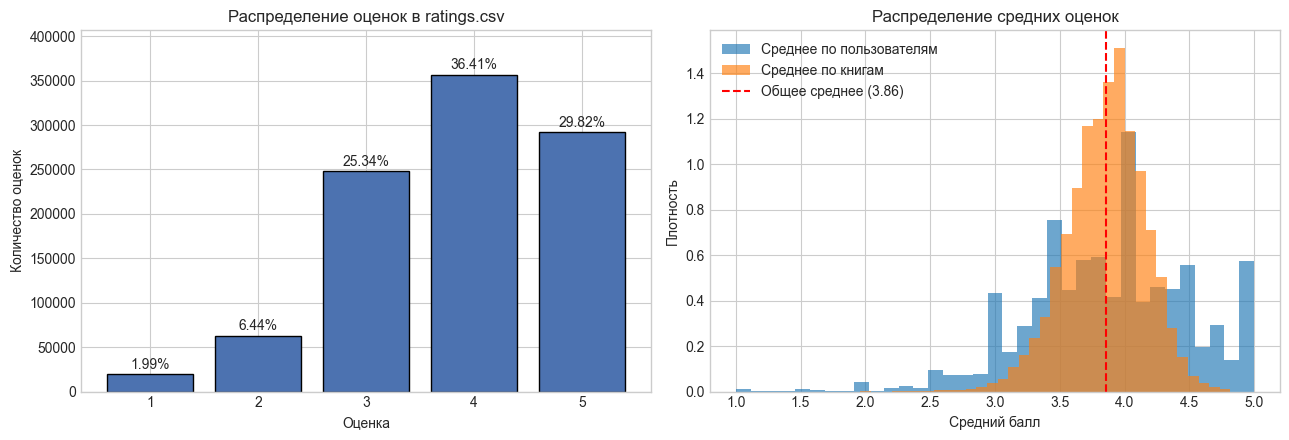

In [3]:
rating_cnt = ratings["rating"].value_counts().sort_index()
rating_pct = (rating_cnt / len(ratings) * 100).round(2)

for r, c, p in zip(rating_cnt.index, rating_cnt.values, rating_pct.values):
    print(f"Оценка {r}: {c:7d} ({p}%)")

mean_r = ratings["rating"].mean()
print(f"Средняя оценка: {mean_r:.3f}, медиана: {ratings['rating'].median()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

bars = axes[0].bar(rating_cnt.index.astype(str), rating_cnt.values, color="#4c72b0", edgecolor="black")
axes[0].set_title("Распределение оценок в ratings.csv")
axes[0].set_xlabel("Оценка")
axes[0].set_ylabel("Количество оценок")
for bar, pct in zip(bars, rating_pct.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 6000, f"{pct}%", ha="center")
axes[0].set_ylim(0, rating_cnt.max() * 1.14)

axes[1].hist(ratings.groupby("user_id")["rating"].mean(), bins=35, alpha=0.65, label="Среднее по пользователям", density=True)
axes[1].hist(ratings.groupby("book_id")["rating"].mean(), bins=35, alpha=0.65, label="Среднее по книгам", density=True)
axes[1].axvline(mean_r, color="red", linestyle="--", label=f"Общее среднее ({mean_r:.2f})")
axes[1].set_title("Распределение средних оценок")
axes[1].set_xlabel("Средний балл")
axes[1].set_ylabel("Плотность")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/01_ratings_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

Оценки 4 и 5 встречаются чаще всего — вместе это 66.2% оценок. Среднее тоже довольно высокое: 3.86. Возможно, люди чаще оценивают книги, которые изначально им интересны. Но проверить причину такого смещения по этим данным нельзя.

### 1.2. Активность пользователей

count    53424.000000
mean        18.334045
std         26.224647
min          1.000000
10%          2.000000
25%          3.000000
50%          8.000000
75%         22.000000
90%         47.000000
99%        134.000000
max        200.000000
dtype: float64
Пользователей с < 5 оценками: 17765 (33.3%)
Пользователей с < 10 оценками: 29050 (54.4%)


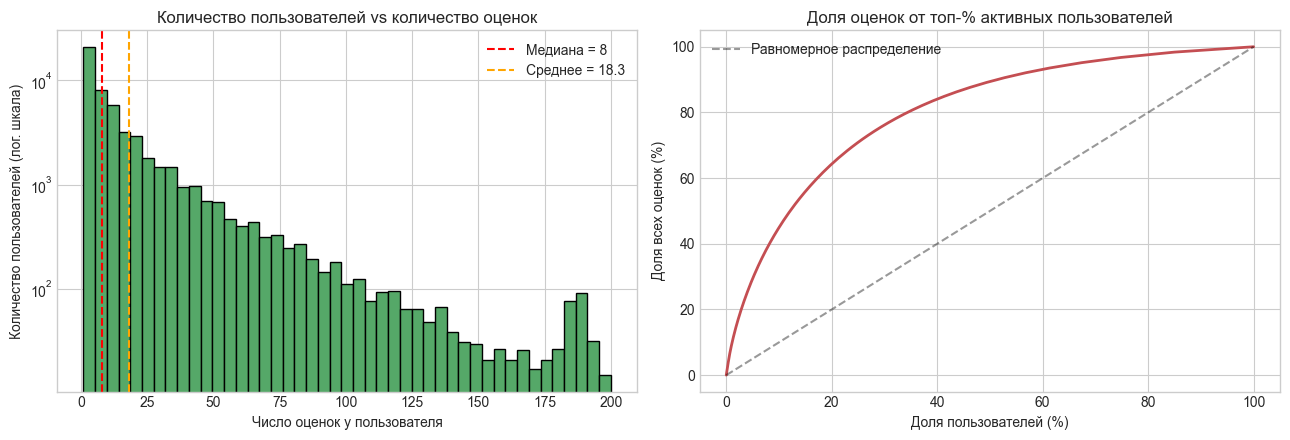

In [4]:
user_counts = ratings.groupby("user_id").size()
print(user_counts.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))
print(f"Пользователей с < 5 оценками: {(user_counts < 5).sum()} ({(user_counts < 5).mean()*100:.1f}%)")
print(f"Пользователей с < 10 оценками: {(user_counts < 10).sum()} ({(user_counts < 10).mean()*100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(user_counts, bins=45, color="#55a868", edgecolor="black")
axes[0].axvline(user_counts.median(), color="red", linestyle="--", label=f"Медиана = {user_counts.median():.0f}")
axes[0].axvline(user_counts.mean(), color="orange", linestyle="--", label=f"Среднее = {user_counts.mean():.1f}")
axes[0].set_yscale("log")
axes[0].set_title("Количество пользователей vs количество оценок")
axes[0].set_xlabel("Число оценок у пользователя")
axes[0].set_ylabel("Количество пользователей (лог. шкала)")
axes[0].legend()

sorted_u = np.sort(user_counts.values)[::-1]
cum_share = np.cumsum(sorted_u) / sorted_u.sum() * 100
user_pct = np.arange(1, len(sorted_u) + 1) / len(sorted_u) * 100
axes[1].plot(user_pct, cum_share, color="#c44e52", linewidth=2)
axes[1].plot([0, 100], [0, 100], "k--", alpha=0.4, label="Равномерное распределение")
axes[1].set_title("Доля оценок от топ-% активных пользователей")
axes[1].set_xlabel("Доля пользователей (%)")
axes[1].set_ylabel("Доля всех оценок (%)")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/02_user_activity.png", dpi=150, bbox_inches="tight")
plt.show()

Медиана — 8 оценок на пользователя. У 33.3% пользователей меньше пяти оценок, у 54.4% — меньше десяти. По такой короткой истории сложно понять вкусы человека. При этом совсем новых пользователей в `ratings.csv` нет, поэтому для проверки холодного старта я отдельно отложу часть пользователей целиком.

### 1.3. Популярность книг и длинный хвост

Сравню число оценок в нашем файле и общий счётчик `ratings_count` из таблицы книг.

Оценки на книгу в ratings.csv:
count    10000.000000
mean        97.947800
std          5.759322
min          8.000000
25%         99.000000
50%        100.000000
75%        100.000000
max        100.000000
dtype: float64

Глобальный ratings_count в books.csv:
count    1.000000e+04
mean     5.400124e+04
std      1.573700e+05
min      2.716000e+03
25%      1.356875e+04
50%      2.115550e+04
75%      4.105350e+04
max      4.780653e+06
Name: ratings_count, dtype: float64


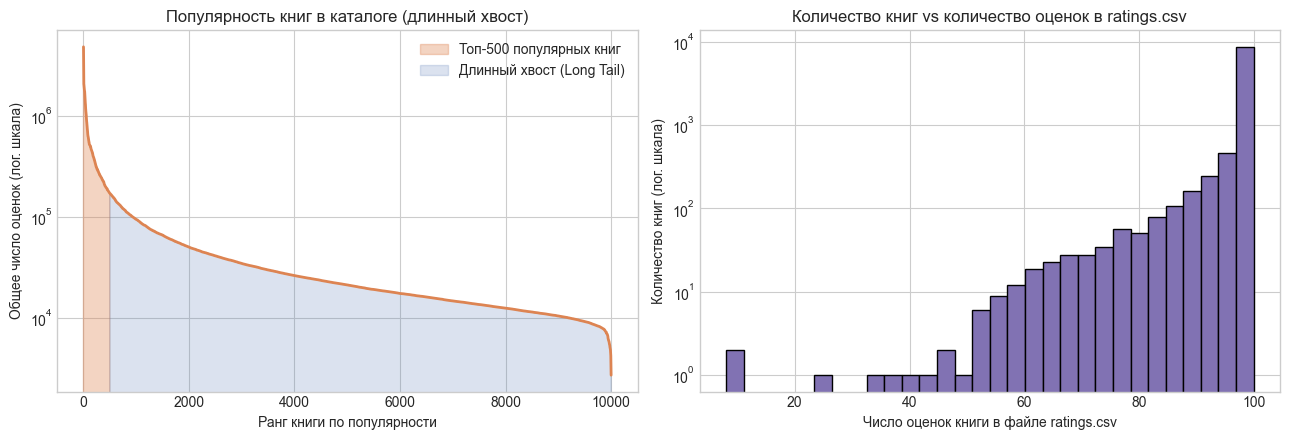

In [5]:
book_counts_local = ratings.groupby("book_id").size()
global_counts = books["ratings_count"].sort_values(ascending=False).values

print("Оценки на книгу в ratings.csv:")
print(book_counts_local.describe())
print("\nГлобальный ratings_count в books.csv:")
print(books["ratings_count"].describe())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(np.arange(1, len(global_counts) + 1), global_counts, color="#dd8452", linewidth=2)
axes[0].fill_between(np.arange(1, 501), global_counts[:500], color="#dd8452", alpha=0.35, label="Топ-500 популярных книг")
axes[0].fill_between(np.arange(501, 10001), global_counts[500:], color="#4c72b0", alpha=0.2, label="Длинный хвост (Long Tail)")
axes[0].set_yscale("log")
axes[0].set_title("Популярность книг в каталоге (длинный хвост)")
axes[0].set_xlabel("Ранг книги по популярности")
axes[0].set_ylabel("Общее число оценок (лог. шкала)")
axes[0].legend()

axes[1].hist(book_counts_local, bins=30, color="#8172b3", edgecolor="black")
axes[1].set_yscale("log")
axes[1].set_title("Количество книг vs количество оценок в ratings.csv")
axes[1].set_xlabel("Число оценок книги в файле ratings.csv")
axes[1].set_ylabel("Количество книг (лог. шкала)")

plt.tight_layout()
plt.savefig("figures/03_book_popularity_long_tail.png", dpi=150, bbox_inches="tight")
plt.show()

По общему числу оценок виден длинный хвост: у нескольких известных книг миллионы оценок, у большинства — десятки тысяч. В локальном `ratings.csv` картина другая: у книги не больше 100 оценок, а у большинства их 95–100. Значит, частота книги в этом файле плохо отражает её настоящую популярность.

### 1.4. Самые частые теги

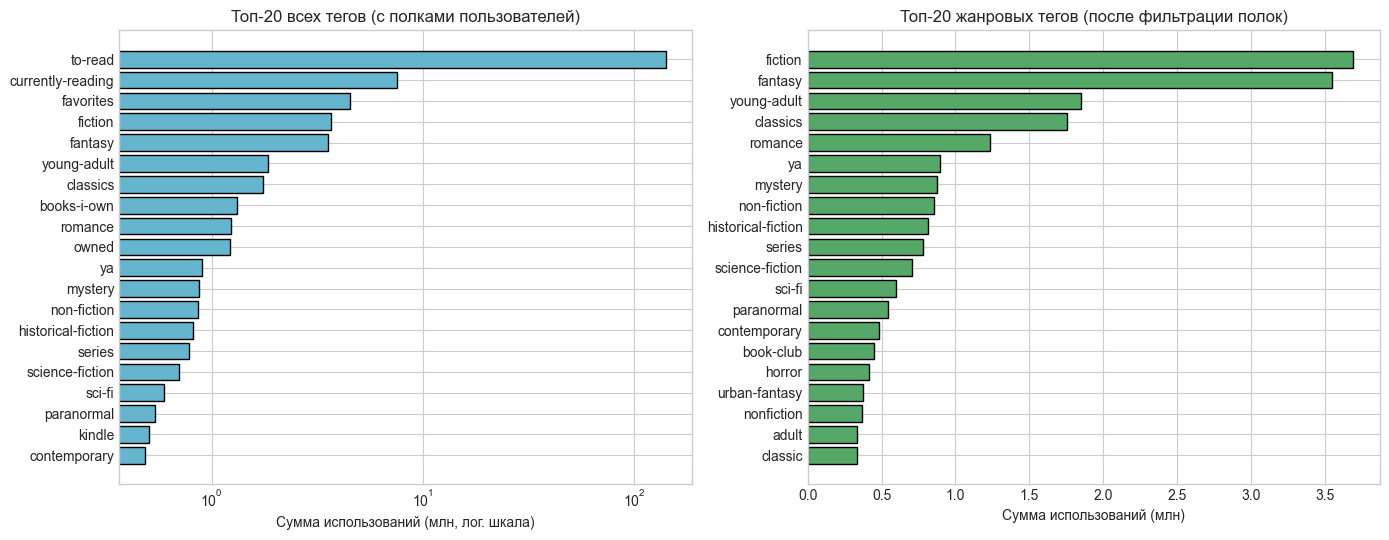

In [6]:
bt_merged = book_tags.merge(tags, on="tag_id", how="left")
bt_merged["tag_name"] = bt_merged["tag_name"].fillna("").astype(str).str.lower().str.strip()

# Топ-20 всех тегов по сумме count
top_raw_tags = bt_merged.groupby("tag_name")["count"].sum().sort_values(ascending=False).head(20)

# Уберу самые частые служебные полки, чтобы они не вытесняли жанры.
stop_tags = {
    "to-read", "currently-reading", "favorites", "favourites", "books-i-own",
    "owned", "owned-books", "library", "my-books", "to-buy", "default",
    "kindle", "ebook", "ebooks", "audiobook", "audiobooks", "audio",
    "wish-list", "my-library", "i-own", "own-it", "read", "have"
}
bt_clean = bt_merged[~bt_merged["tag_name"].isin(stop_tags) & (bt_merged["tag_name"].str.len() > 1)]
top_genre_tags = bt_clean.groupby("tag_name")["count"].sum().sort_values(ascending=False).head(20)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].barh(top_raw_tags.index[::-1], top_raw_tags.values[::-1] / 1e6, color="#64b5cd", edgecolor="black")
axes[0].set_xscale("log")
axes[0].set_title("Топ-20 всех тегов (с полками пользователей)")
axes[0].set_xlabel("Сумма использований (млн, лог. шкала)")

axes[1].barh(top_genre_tags.index[::-1], top_genre_tags.values[::-1] / 1e6, color="#55a868", edgecolor="black")
axes[1].set_title("Топ-20 жанровых тегов (после фильтрации полок)")
axes[1].set_xlabel("Сумма использований (млн)")

plt.tight_layout()
plt.savefig("figures/04_top_book_tags.png", dpi=150, bbox_inches="tight")
plt.show()

### 1.5. Что видно по данным

1. Матрица оценок очень разреженная: заполнено около 0.183% ячеек, остальные 99.82% пустые. Пустая ячейка не означает, что книга пользователю не понравилась.
2. По общим счётчикам Goodreads заметно смещение популярности: у хитов гораздо больше оценок. В нашем `ratings.csv` длинный хвост сглажен ограничением примерно в 100 оценок на книгу.
3. У большинства пользователей небольшая история. Для новых пользователей придётся начать с популярных книг или спросить об их интересах.
4. Оценки смещены вверх. Дальше буду считать книгу релевантной, если пользователь поставил ей 4 или 5.
5. Среди тегов много служебных полок вроде `to-read` и `owned`. Уберу самые очевидные из них, хотя полностью очистить теги простым списком не получится.
6. Дат оценок нет, поэтому разделить взаимодействия по времени нельзя. Буду использовать случайное разбиение. Теги и описание каталога считаю уже доступными: исторических версий этих таблиц у меня нет.

## Этап 2. Разделение данных и базовые модели

Для проверки холодного старта сначала отложу 300 пользователей со всей их историей и 100 книг со всеми оценками остальных пользователей. Если оценка относится и к новому пользователю, и к новой книге, она попадёт в тест новых пользователей.

Остальные оценки перемешаю внутри каждого пользователя: около 20% отложу в test, затем около 20% оставшихся — в validation. Если на текущем шаге у пользователя меньше пяти оценок, оставлю их в обучении. Поэтому общие доли будут немного отличаться от 64/16/20.

На validation выберу параметры SVD и веса гибрида. Потом обучу модели заново на train + validation. Test оставлю для итогового сравнения.

In [7]:
rng = np.random.default_rng(SEED)
possible_cold_users = user_counts[user_counts >= 5].index.to_numpy()
cold_user_ids = np.sort(rng.choice(possible_cold_users, size=300, replace=False))
cold_book_ids = np.sort(rng.choice(books["id"].to_numpy(), size=100, replace=False))

is_cold_user = ratings["user_id"].isin(cold_user_ids)
is_cold_book = ratings["book_id"].isin(cold_book_ids)
cold_user_test = ratings[is_cold_user].copy()
cold_book_test = ratings[~is_cold_user & is_cold_book].copy()
main_ratings = ratings[~is_cold_user & ~is_cold_book].copy()


def split_by_user(frame, fraction=0.2, seed=SEED):
    shuffled = frame.sample(frac=1, random_state=seed).reset_index(drop=True)
    count = shuffled.groupby("user_id")["book_id"].transform("size")
    position = shuffled.groupby("user_id").cumcount()
    n_holdout = np.where(count >= 5, np.maximum(1, (count * fraction).astype(int)), 0)
    held = position < n_holdout
    return shuffled[~held].reset_index(drop=True), shuffled[held].reset_index(drop=True)


train_valid, test_df = split_by_user(main_ratings)
train_df, valid_df = split_by_user(train_valid, seed=SEED + 1)


def pair_index(frame):
    return pd.MultiIndex.from_frame(frame[["user_id", "book_id"]])


parts = {"train": train_df, "validation": valid_df, "test": test_df,
         "cold_user_test": cold_user_test, "cold_book_test": cold_book_test}
for name_a, a in parts.items():
    for name_b, b in parts.items():
        if name_a < name_b:
            assert pair_index(a).intersection(pair_index(b)).empty
assert sum(map(len, parts.values())) == len(ratings)
assert not train_valid["user_id"].isin(cold_user_ids).any()
assert not train_valid["book_id"].isin(cold_book_ids).any()
display(pd.DataFrame({name: {"Оценки": len(frame), "Пользователи": frame.user_id.nunique(),
                                   "Книги": frame.book_id.nunique()} for name, frame in parts.items()}).T)

,Оценки,Пользователи,Книги
train,658343,53124,9900
validation,134308,32020,9896
test,170108,35239,9899
cold_user_test,6925,300,4976
cold_book_test,9794,7844,100


### 2.1. Popularity: средний рейтинг с порогом числа оценок

Начну с простого бейзлайна из задания: возьму книги хотя бы с 30 оценками и отсортирую их по среднему рейтингу. Порог задаю до сравнения моделей.

Средние и число оценок посчитаю по обучающей части. Готовые `average_rating` и `ratings_count` из каталога здесь использовать не буду — они пригодились только в EDA.

Сразу подготовлю разреженные матрицы для следующих моделей. В implicit-матрице единица будет означать оценку 4 или 5, а нулевые значения хранить не нужно.

In [8]:
MIN_RATINGS = 30
K_NEIGHBORS = 50


def make_state(frame):
    u = frame.user_id.to_numpy(dtype=np.int64) - 1
    i = frame.book_id.to_numpy(dtype=np.int64) - 1
    r = frame.rating.to_numpy(dtype=np.float32)
    R = sparse.csr_matrix((r, (u, i)), shape=(n_users, n_books), dtype=np.float32)
    seen = R.copy()
    seen.data[:] = 1
    implicit = R.copy()
    implicit.data = (implicit.data >= 4).astype(np.float32)
    implicit.eliminate_zeros()
    positive = R.copy()
    positive.data = np.where(positive.data >= 4, positive.data - 3, 0).astype(np.float32)
    positive.eliminate_zeros()
    uc = np.asarray(seen.sum(axis=1)).ravel()
    ic = np.asarray(seen.sum(axis=0)).ravel()
    mean = float(r.mean())
    um = np.divide(np.asarray(R.sum(axis=1)).ravel(), uc,
                   out=np.full(n_users, mean, dtype=np.float32), where=uc > 0)
    im = np.divide(np.asarray(R.sum(axis=0)).ravel(), ic,
                   out=np.full(n_books, mean, dtype=np.float32), where=ic > 0)
    centered = sparse.csr_matrix((r - um[u], (u, i)), shape=R.shape)
    trainset = Dataset.load_from_df(frame[["user_id", "book_id", "rating"]], Reader(rating_scale=(1, 5))).build_full_trainset()
    return dict(trainset=trainset, R=R, seen=seen, implicit=implicit, positive=positive,
                user_count=uc, item_count=ic, user_mean=um, item_mean=im,
                centered=centered, mean=mean, u=u, i=i, r=r)


def popularity_scores(state):
    return state["item_mean"].copy()


def popular_candidates(state):
    eligible = state["item_count"] >= MIN_RATINGS
    # На маленькой подвыборке порог может оказаться недостижим.
    return eligible if eligible.any() else state["item_count"] > 0


selection_state = make_state(train_df)
print("Train CSR:", selection_state["R"].shape, "оценок:", selection_state["R"].nnz)
print("Положительных implicit-взаимодействий:", selection_state["implicit"].nnz)

Train CSR: (53424, 10000) оценок: 658343
Положительных implicit-взаимодействий: 436218


### 2.2. Контентная модель: TF-IDF

Для каждой книги соберу текст из названия, автора и 30 самых частых очищенных тегов. Если `original_title` пропущен, возьму `title`. Затем применю TF-IDF.

У векторов единичная L2-норма, поэтому скалярное произведение даст косинусную близость. По ней и найду похожие книги.

Здесь я предполагаю, что название, автор и теги доступны и для книги без оценок. Это упрощение: проверить, какие теги были известны раньше, по данным нельзя. При этом тестовые оценки в профили пользователей не попадут.

In [9]:
bt_top = (bt_clean[bt_clean["count"] >= 5]
          .sort_values(["goodreads_book_id", "count"], ascending=[True, False])
          .groupby("goodreads_book_id").head(30))
tags_per_book = (bt_top.groupby("goodreads_book_id")["tag_name"]
                 .apply(lambda s: " ".join(s.str.replace("-", " ", regex=False)))
                 .rename("tags_str"))
books = books.merge(tags_per_book, left_on="book_id", right_index=True, how="left", validate="one_to_one")
books["clean_title"] = books.original_title.fillna(books.title).fillna("")
books["profile"] = (books.clean_title + " " + books.authors.fillna("") + " " + books.tags_str.fillna(""))
tfidf = TfidfVectorizer(max_features=15000, stop_words="english", ngram_range=(1, 2),
                        min_df=2, max_df=0.85, sublinear_tf=True, dtype=np.float32)
tfidf_matrix = tfidf.fit_transform(books.profile).tocsr()
print("TF-IDF:", tfidf_matrix.shape)


def top_indices(scores, N, allowed=None):
    if isinstance(N, bool) or not isinstance(N, (int, np.integer)) or N < 1:
        raise ValueError("N должно быть положительным целым числом")
    values = np.asarray(scores).copy()
    if allowed is not None:
        values[~allowed] = -np.inf
    # При равных значениях первым будет меньший ID книги.
    order = np.argsort(-values, kind="stable")
    return order[np.isfinite(values[order])][:N]


def get_similar_books(book_id, N=5):
    if isinstance(book_id, bool) or not isinstance(book_id, (int, np.integer)) or not 1 <= book_id <= n_books:
        raise ValueError("Ожидается внутренний book_id из ratings.csv")
    idx = int(book_id) - 1
    scores = (tfidf_matrix[idx] @ tfidf_matrix.T).toarray().ravel()
    scores[idx] = -np.inf
    order = top_indices(scores, N)
    result = books.iloc[order][["id", "clean_title", "authors"]].copy()
    result["cosine_similarity"] = scores[order]
    return result.reset_index(drop=True)


display(get_similar_books(1))

TF-IDF: (10000, 15000)


,id,clean_title,authors,cosine_similarity
0,507,The Hunger Games Box Set,Suzanne Collins,0.747087
1,20,Mockingjay,Suzanne Collins,0.740908
2,17,Catching Fire,Suzanne Collins,0.718021
3,6224,The World of the Hunger Games (Hunger Games Tr...,Kate Egan,0.625896
4,1355,The Hunger Games Tribute Guide,Emily Seife,0.438928


## Этап 3. Item-Based Collaborative Filtering

Теперь сравню книги по векторам пользовательских оценок. Для каждой книги оставлю 50 ближайших соседей по косинусной близости. Сходства буду считать блоками по 256 книг, чтобы не хранить плотную матрицу 10 000 × 10 000.

Для прогноза возьму среднюю оценку пользователя и добавлю взвешенные отклонения его оценок соседних книг от этого среднего. В знаменателе будут только сходства с теми соседями, которые пользователь оценил. Если таких соседей нет, возьму полусумму средних пользователя и книги.

Прогноз ограничу диапазоном от 1 до 5. Для RMSE и рекомендаций буду использовать эту же формулу.

In [10]:
def fit_item_neighbors(state, k=K_NEIGHBORS, block_size=256):
    item_vectors = normalize(state["R"].T.tocsr(), norm="l2", axis=1)
    row_parts, col_parts, value_parts = [], [], []
    for start in range(0, n_books, block_size):
        end = min(start + block_size, n_books)
        sims = (item_vectors[start:end] @ item_vectors.T).toarray()
        sims[np.arange(end - start), np.arange(start, end)] = 0
        take = min(k, n_books - 1)
        neighbors = np.argpartition(sims, -take, axis=1)[:, -take:]
        rows = np.repeat(np.arange(start, end), take)
        cols = neighbors.ravel()
        values = sims[np.repeat(np.arange(end - start), take), cols]
        positive = values > 0
        row_parts.append(rows[positive]); col_parts.append(cols[positive]); value_parts.append(values[positive])
    return sparse.csr_matrix((np.concatenate(value_parts),
                             (np.concatenate(row_parts), np.concatenate(col_parts))),
                            shape=(n_books, n_books), dtype=np.float32)


def finish_cf_prediction(user_mean, item_mean, numerator, denominator):
    fallback = 0.5 * user_mean + 0.5 * item_mean
    predictions = np.where(denominator > 1e-6,
                           user_mean + numerator / np.maximum(denominator, 1e-6), fallback)
    return np.clip(predictions, 1, 5)


def cf_scores(state, user_idx):
    num = (state["centered"][user_idx] @ state["neighbors"].T).toarray()
    den = (state["seen"][user_idx] @ abs(state["neighbors"]).T).toarray()
    return finish_cf_prediction(state["user_mean"][user_idx, None], state["item_mean"][None, :], num, den)


t0 = time.perf_counter()
selection_state["neighbors"] = fit_item_neighbors(selection_state)
print(f"Item-CF: {time.perf_counter() - t0:.2f} с, связей: {selection_state['neighbors'].nnz:,}")

Item-CF: 0.55 с, связей: 494,943


### 3.1. Вычислительная сложность

Если сравнивать все пары книг по плотным векторам, получится O(I²U) по времени и O(I²) по памяти, где I — число книг, U — число пользователей. При разреженном умножении многое зависит от пересечений историй. Число вкладов связано с суммой квадратов длин пользовательских историй: очень активные пользователи делают расчёт дороже.

Блоки уменьшают объём плотной рабочей памяти до O(BI), а хранение K соседей на книгу требует O(IK). Но сами пары всё равно приходится сравнивать. Один блок float32 размером 256 × 10 000 занимает примерно 10 МБ. Кроме него, нужна память под индексы соседей и промежуточные результаты.

Для большего каталога я бы попробовал поиск приближённых соседей после уменьшения размерности, отбор кандидатов по общим оценкам или разреженное умножение с сохранением только top-K. Ещё один вариант — перейти к ALS/SVD.

## Этап 4. Матричная факторизация: SVD из Surprise

Для матричной факторизации возьму `surprise.SVD`. Его прогноз имеет вид:

$\hat r_{ui}=\mu+b_u+b_i+p_u^Tq_i$.

Здесь μ — среднее по обучению, b — смещения пользователя и книги, p и q — их факторы. Модель обучается по наблюдаемым оценкам с регуляризацией. Пропуски не заменяются нулевыми оценками. Формулу можно посмотреть в [документации Surprise](https://surprise.readthedocs.io/en/stable/matrix_factorization.html).

Чтобы быстро получить прогнозы сразу для всего каталога, перенесу обученные факторы в массивы с нашими ID. Отдельно проверю, что результат совпадает с `algo.predict`. Для неизвестных объектов смещения и факторы будут нулевыми.

Проверю 32 и 64 фактора, регуляризацию 0.04 и 0.10, а также 10, 20 и 30 эпох. Выберу вариант с меньшим validation RMSE, после чего переобучу его на train + validation. Рекомендации будут отсортированы по предсказанному рейтингу.

In [11]:
def svd_pair_predictions(model, user_idx, item_idx, batch_size=32768):
    mu, bu, bi, P, Q, _ = model
    result = np.empty(len(user_idx), dtype=np.float64)
    for start in range(0, len(user_idx), batch_size):
        end = start + batch_size
        u, i = user_idx[start:end], item_idx[start:end]
        result[start:end] = np.clip(mu + bu[u] + bi[i] + np.sum(P[u] * Q[i], axis=1), 1, 5)
    return result


def fit_svd(state, n_factors=32, reg=0.04, n_epochs=20):
    trainset = state["trainset"]
    algo = SVD(n_factors=n_factors, n_epochs=n_epochs, reg_all=reg,
               lr_all=0.007, random_state=SEED).fit(trainset)
    raw_users = np.array([int(trainset.to_raw_uid(u)) - 1 for u in trainset.all_users()])
    raw_books = np.array([int(trainset.to_raw_iid(i)) - 1 for i in trainset.all_items()])
    bu = np.zeros(n_users); bi = np.zeros(n_books)
    P = np.zeros((n_users, n_factors)); Q = np.zeros((n_books, n_factors))
    bu[raw_users] = algo.bu; bi[raw_books] = algo.bi
    P[raw_users] = algo.pu; Q[raw_books] = algo.qi
    model = (float(trainset.global_mean), bu, bi, P, Q, None)
    # Проверка переноса внутренних индексов Surprise в ID исходного датасета.
    check_u, check_i = state["u"][:10], state["i"][:10]
    library = np.array([algo.predict(int(u + 1), int(i + 1)).est for u, i in zip(check_u, check_i)])
    assert np.allclose(svd_pair_predictions(model, check_u, check_i), library, atol=1e-10)
    return model


svd_trials = []
vu = valid_df.user_id.to_numpy(dtype=np.int64) - 1
vi = valid_df.book_id.to_numpy(dtype=np.int64) - 1
vr = valid_df.rating.to_numpy()
for factors in (32, 64):
    for reg in (0.04, 0.10):
        for epochs in (10, 20, 30):
            model = fit_svd(selection_state, n_factors=factors, reg=reg, n_epochs=epochs)
            val_predictions = svd_pair_predictions(model, vu, vi)
            train_predictions = svd_pair_predictions(model, selection_state["u"], selection_state["i"])
            svd_trials.append(dict(factors=factors, reg=reg, epochs=epochs,
                validation_RMSE=float(np.sqrt(np.mean((vr - val_predictions) ** 2))),
                train_RMSE=float(np.sqrt(np.mean((selection_state["r"] - train_predictions) ** 2)))))
svd_search = pd.DataFrame(svd_trials).sort_values(["validation_RMSE", "factors", "reg", "epochs"])
best_svd = svd_search.iloc[0]
svd_parameters = dict(n_factors=int(best_svd.factors), reg=float(best_svd.reg), n_epochs=int(best_svd.epochs))
selection_state["svd"] = fit_svd(selection_state, **svd_parameters)
display(svd_search.reset_index(drop=True))
print("Выбрано по validation:", svd_parameters)

,factors,reg,epochs,validation_RMSE,train_RMSE
0,64,0.10,30,0.828914,0.673816
1,32,0.10,30,0.829428,0.721080
2,32,0.10,20,0.831508,0.753147
3,64,0.10,20,0.831604,0.719639
4,32,0.04,20,0.833104,0.714014
5,64,0.04,20,0.834773,0.652281
6,32,0.04,30,0.834921,0.632942
7,64,0.04,30,0.836984,0.540893
8,32,0.10,10,0.837776,0.787080
9,32,0.04,10,0.838095,0.775780


Выбрано по validation: {'n_factors': 64, 'reg': 0.1, 'n_epochs': 30}


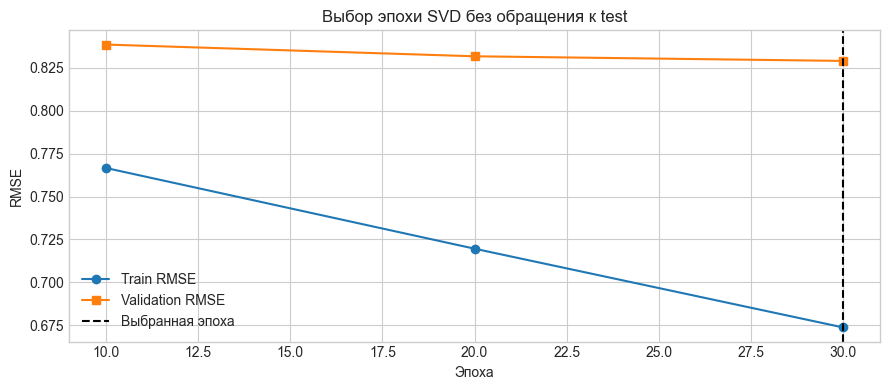

In [12]:
history = svd_search[(svd_search.factors == svd_parameters["n_factors"])
                     & (svd_search.reg == svd_parameters["reg"])].sort_values("epochs")
plt.figure(figsize=(9, 4))
plt.plot(history.epochs, history.train_RMSE, "o-", label="Train RMSE")
plt.plot(history.epochs, history.validation_RMSE, "s-", label="Validation RMSE")
plt.axvline(svd_parameters["n_epochs"], color="black", linestyle="--", label="Выбранная эпоха")
plt.xlabel("Эпоха"); plt.ylabel("RMSE"); plt.title("Выбор эпохи SVD без обращения к test")
plt.legend(); plt.tight_layout()
plt.savefig(FIGURES / "06_svd_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()

## Этап 5. Рекомендации и сравнение моделей

### 5.1. Контентный профиль и гибрид

Для контентной выдачи усредню TF-IDF-векторы книг, которым пользователь поставил 4 или 5. Их веса будут 1 и 2 соответственно. Если положительных оценок ещё нет, верну популярные книги.

В гибриде приведу значения CF, SVD и контентной модели к диапазону [0, 1] по непрочитанным книгам. Для активных пользователей выберу веса по validation nDCG@5 из небольшой сетки. Если оценок всего 1–4, задам 70% веса контенту. Для новой книги без оценок останется контентная модель, а для пользователя без истории — Popularity.

Значение гибрида нужно для сортировки, это не прогноз оценки от 1 до 5. Поэтому RMSE для него и Content-Based считать не буду. У Popularity, CF и SVD прогноз рейтинга используется и для сортировки; у Popularity дополнительно есть порог числа оценок.

In [13]:
MODELS = ["Popularity", "Content-Based", "Item-Based CF", "SVD", "Hybrid"]


def hybrid_weights(n_ratings, selected_weights):
    """Веса CF, SVD и контентной модели в зависимости от длины истории."""
    if n_ratings < 5:
        return (0.20, 0.10, 0.70)
    return selected_weights


def svd_scores(state, user_idx):
    mu, bu, bi, P, Q, _ = state["svd"]
    return np.clip(mu + bu[user_idx, None] + bi[None, :] + P[user_idx] @ Q.T, 1, 5)


def content_scores(state, user_idx):
    profiles = normalize(state["positive"][user_idx] @ tfidf_matrix, norm="l2", axis=1)
    scores = (profiles @ tfidf_matrix.T).toarray()
    no_likes = state["positive"][user_idx].getnnz(axis=1) == 0
    if no_likes.any():
        scores[no_likes] = popularity_scores(state)
    return scores


def normalize_scores(values, available):
    minimum = np.min(np.where(available, values, np.inf), axis=1, keepdims=True)
    maximum = np.max(np.where(available, values, -np.inf), axis=1, keepdims=True)
    minimum = np.where(np.isfinite(minimum), minimum, 0)
    maximum = np.where(np.isfinite(maximum), maximum, 0)
    return np.where(available, (values - minimum) / np.maximum(maximum - minimum, 1e-8), 0)


def all_model_scores(state, user_ids, weights, candidates=None):
    ids = np.asarray(user_ids, dtype=np.int64)
    known_id = (ids >= 1) & (ids <= n_users)
    user_idx = np.clip(ids - 1, 0, n_users - 1)
    has_history = known_id & (state["user_count"][user_idx] > 0)
    seen = state["seen"][user_idx].toarray().astype(bool)
    seen[~has_history] = False
    available = ~seen
    if candidates is not None:
        available &= candidates[None, :]
    pop = np.broadcast_to(popularity_scores(state), seen.shape).copy()
    cf = cf_scores(state, user_idx)
    svd = svd_scores(state, user_idx)
    content = content_scores(state, user_idx)
    cf_unit = normalize_scores(cf, available)
    svd_unit = normalize_scores(svd, available)
    cb_unit = normalize_scores(content, available)
    user_weights = np.array([hybrid_weights(state["user_count"][u], weights) for u in user_idx])
    hybrid = (user_weights[:, 0, None] * cf_unit + user_weights[:, 1, None] * svd_unit
              + user_weights[:, 2, None] * cb_unit)
    # Для книг без оценок использую контентную близость.
    cold_books = state["item_count"] == 0
    hybrid[:, cold_books] = cb_unit[:, cold_books]
    no_likes = state["positive"][user_idx].getnnz(axis=1) == 0
    hybrid[no_likes] = pop[no_likes]
    result = {"Popularity": pop, "Content-Based": content, "Item-Based CF": cf, "SVD": svd, "Hybrid": hybrid}
    for name, scores in result.items():
        fallback_pop = ~has_history
        if name in ("Content-Based", "Hybrid"):
            fallback_pop = fallback_pop | no_likes
        scores[fallback_pop] = pop[fallback_pop]
        scores[~available] = -np.inf
        if name == "Popularity":
            scores[:, ~popular_candidates(state)] = -np.inf
        # При возврате к Popularity сохраняю порог числа оценок.
        scores[np.ix_(fallback_pop, ~popular_candidates(state))] = -np.inf
    return result


def precision_at_k(recommended, relevant, k):
    return sum(item in relevant for item in recommended[:k]) / k


def recall_at_k(recommended, relevant, k):
    return sum(item in relevant for item in recommended[:k]) / len(relevant) if relevant else 0.0


def ndcg_at_k(recommended, relevant, k):
    if not relevant:
        return 0.0
    hits = np.array([item in relevant for item in recommended[:k]], dtype=np.float64)
    dcg = np.sum(hits / np.log2(np.arange(len(hits)) + 2))
    ideal = np.sum(1 / np.log2(np.arange(min(k, len(relevant))) + 2))
    return float(dcg / ideal)


assert precision_at_k([1, 2, 3, 4, 5], {1, 3, 8}, 5) == 0.4
assert recall_at_k([1, 2, 3, 4, 5], {1, 3, 8}, 5) == 2 / 3
assert np.isclose(ndcg_at_k([1, 2, 3, 4, 5], {1, 3, 8}, 5), 1.5 / (1 + 1/np.log2(3) + 0.5))
assert ndcg_at_k([1, 2], set(), 5) == 0
assert np.isclose(ndcg_at_k([1, 3, 8], {1, 3, 8}, 3), 1)

### 5.2. Как буду считать метрики

Релевантными считаю отложенные книги с оценкой 4 или 5. Сначала посчитаю Precision, Recall и nDCG для каждого пользователя, потом усредню. Пользователей без релевантных отложенных книг в это сравнение не включаю.

Для основного сравнения случайно выберу до 2500 пользователей с релевантными тестовыми книгами и историей в обучении. Длину истории дополнительно ограничивать не буду. Каждая модель будет ранжировать **все книги с обучающими оценками**, кроме уже оценённых этим пользователем. У Popularity останется её порог числа оценок. В отдельной проверке новых книг буду использовать весь каталог.

Если рекомендаций меньше K, в Precision всё равно делю на K. В nDCG учитываю порядок выдачи и сравниваю её с идеальным списком длины min(K, число релевантных книг). При равных значениях первым идёт меньший ID.

Если у книги нет тестовой оценки, она не даст попадания в метрике. Это не значит, что книга человеку не понравилась: просто такого наблюдения нет. Из-за разреженности данных это важное ограничение сравнения. RMSE отдельно посчитаю по всем оценкам основного test.

In [14]:
def evaluation_users(frame, state, limit, seed, require_history=True):
    relevant = frame[frame.rating >= 4].groupby("user_id")["book_id"].apply(set).to_dict()
    eligible = np.array(sorted(u for u in relevant if not require_history or state["user_count"][u - 1] > 0), dtype=np.int64)
    sampled = np.sort(np.random.default_rng(seed).choice(eligible, size=min(limit, len(eligible)), replace=False))
    return sampled, relevant, len(eligible)


def evaluate_ranking(state, frame, user_ids, weights, candidates=None, batch_size=64):
    relevant = frame[frame.rating >= 4].groupby("user_id")["book_id"].apply(set).to_dict()
    records = []
    for start in range(0, len(user_ids), batch_size):
        batch = user_ids[start:start + batch_size]
        scores_by_model = all_model_scores(state, batch, weights, candidates)
        for name, scores in scores_by_model.items():
            for row, user in enumerate(batch):
                recs = top_indices(scores[row], 10) + 1
                rel = relevant[int(user)]
                record = {"model": name, "user_id": int(user)}
                for k in (5, 10):
                    record[f"Precision@{k}"] = precision_at_k(recs, rel, k)
                    record[f"Recall@{k}"] = recall_at_k(recs, rel, k)
                    record[f"nDCG@{k}"] = ndcg_at_k(recs, rel, k)
                records.append(record)
    per_user = pd.DataFrame(records)
    metrics = per_user.groupby("model", sort=False).mean(numeric_only=True).drop(columns="user_id").reindex(MODELS)
    return metrics, per_user


valid_users, _, n_valid_eligible = evaluation_users(valid_df, selection_state, 800, SEED + 2)
# Заранее задам варианты весов в порядке CF, SVD, Content.
weight_grid = [(0.6, 0.2, 0.2), (0.2, 0.6, 0.2), (0.2, 0.2, 0.6), (0.4, 0.0, 0.6)]
weight_trials = []
for weights in weight_grid:
    metrics, _ = evaluate_ranking(selection_state, valid_df, valid_users, weights,
                                  candidates=selection_state["item_count"] > 0)
    weight_trials.append({"weights_CF_SVD_Content": weights, "validation_nDCG@5": metrics.loc["Hybrid", "nDCG@5"]})
weight_search = pd.DataFrame(weight_trials).sort_values("validation_nDCG@5", ascending=False, kind="stable")
selected_weights = tuple(weight_search.iloc[0]["weights_CF_SVD_Content"])
display(weight_search.reset_index(drop=True))
print("Validation ranking:", len(valid_users), "пользователей из", n_valid_eligible)
validation_baselines = metrics.drop(index="Hybrid").copy()


,weights_CF_SVD_Content,validation_nDCG@5
0,"(0.2, 0.2, 0.6)",0.113533
1,"(0.4, 0.0, 0.6)",0.110167
2,"(0.6, 0.2, 0.2)",0.067731
3,"(0.2, 0.6, 0.2)",0.058324


Validation ranking: 800 пользователей из 27108


### 5.3. Финальное обучение и функции рекомендаций

Параметры выбраны. Объединю train и validation, заново обучу CF и SVD и построю контентные профили пользователей.

`get_recommendations` вернёт топ по прогнозу SVD, `get_hybrid_recommendations` — выдачу гибрида. Через `recommend` можно вызвать любую модель. Если пользователя нет в обучении, функция вернёт популярные книги.

In [15]:
final_state = make_state(train_valid)
final_state["neighbors"] = fit_item_neighbors(final_state)
final_state["svd"] = fit_svd(final_state, **svd_parameters)
known_candidates = final_state["item_count"] > 0
assert known_candidates[test_df.book_id.to_numpy() - 1].all()


def recommend(user_id, N=5, model="SVD", candidates=None):
    if isinstance(user_id, bool) or not isinstance(user_id, (int, np.integer)) or user_id < 1:
        raise ValueError("user_id должен быть положительным целым числом")
    if model not in MODELS:
        raise ValueError(f"Неизвестная модель: {model}")
    scores = all_model_scores(final_state, [user_id], selected_weights, candidates)[model][0]
    order = top_indices(scores, N)
    result = books.iloc[order][["id", "clean_title", "authors"]].copy()
    result["score"] = scores[order]
    if model in ("Popularity", "Item-Based CF", "SVD"):
        result = result.rename(columns={"score": "predicted_rating"})
    return result.reset_index(drop=True)


def get_recommendations(user_id, N=5):
    return recommend(user_id, N, model="SVD")


def get_hybrid_recommendations(user_id, N=5):
    return recommend(user_id, N, model="Hybrid")


def get_popular_books(N=10):
    return recommend(n_users + 1, N, model="Popularity")


example_user = int(np.flatnonzero(final_state["user_count"] >= 15)[0] + 1)
print("Пример SVD для пользователя", example_user)
display(get_recommendations(example_user))
print("Рекомендации гибрида для того же пользователя")
display(get_hybrid_recommendations(example_user))

Пример SVD для пользователя 7


,id,clean_title,authors,predicted_rating
0,862,Words of Radiance,Brandon Sanderson,4.740970
1,4868,Jesus the Christ: A Study of the Messiah and H...,James E. Talmage,4.705608
2,5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson,4.699506
3,6920,The Indispensable Calvin and Hobbes: A Calvin ...,Bill Watterson,4.692887
4,6590,The Authoritative Calvin and Hobbes,Bill Watterson,4.686120


Рекомендации гибрида для того же пользователя


,id,clean_title,authors,score
0,1519,The Diamond Age,Neal Stephenson,0.875397
1,5506,Embassytown,China Miéville,0.865176
2,729,Hyperion,Dan Simmons,0.864043
3,442,Snow Crash,Neal Stephenson,0.855891
4,7120,黑暗森林,"Liu Cixin, Joel Martinsen",0.843124


In [16]:
def predict_rating_pairs(state, user_ids, book_ids, model):
    u = np.asarray(user_ids, dtype=np.int64) - 1
    i = np.asarray(book_ids, dtype=np.int64) - 1
    if model == "Popularity":
        return state["item_mean"][i]
    if model == "SVD":
        return svd_pair_predictions(state["svd"], u, i)
    if model == "Item-Based CF":
        neighbors = state["neighbors"][i]
        num = np.asarray(state["centered"][u].multiply(neighbors).sum(axis=1)).ravel()
        den = np.asarray(state["seen"][u].multiply(abs(neighbors)).sum(axis=1)).ravel()
        return finish_cf_prediction(state["user_mean"][u], state["item_mean"][i], num, den)
    raise ValueError("Content-Based и Hybrid не предсказывают оценки")


eval_users, rel_by_user, n_eligible = evaluation_users(test_df, final_state, 2500, SEED + 3)
results_df, per_user_metrics = evaluate_ranking(final_state, test_df, eval_users, selected_weights, known_candidates)
results_df.insert(0, "RMSE", np.nan)
for model in ("Popularity", "Item-Based CF", "SVD"):
    preds = predict_rating_pairs(final_state, test_df.user_id.to_numpy(), test_df.book_id.to_numpy(), model)
    results_df.loc[model, "RMSE"] = np.sqrt(np.mean((test_df.rating.to_numpy() - preds) ** 2))
results_df.index.name = "Модель"
display(results_df.round(4))
print(f"Ranking: {len(eval_users)} пользователей из {n_eligible} подходящих; test RMSE: {len(test_df):,} оценок")
print("Число обучающих оценок у ranking-пользователей:")
display(pd.Series(final_state["user_count"][eval_users - 1]).describe())
results_df.to_csv(RESULTS / "model_comparison.csv")
per_user_metrics.to_csv(RESULTS / "ranking_per_user.csv", index=False)

,RMSE,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10
Модель,,,,,,,
Popularity,0.9460,0.0002,0.0004,0.0004,0.0004,0.0013,0.0008
Content-Based,NaN,0.0820,0.1411,0.1400,0.0584,0.1927,0.1533
Item-Based CF,0.8678,0.0016,0.0038,0.0023,0.0021,0.0117,0.0050
SVD,0.8228,0.0002,0.0004,0.0005,0.0003,0.0014,0.0008
Hybrid,NaN,0.0809,0.1420,0.1377,0.0581,0.1887,0.1500


Ranking: 2500 пользователей из 30191 подходящих; test RMSE: 170,108 оценок
Число обучающих оценок у ranking-пользователей:


count    2500.000000
mean       23.129999
std        23.464384
min         4.000000
25%         8.000000
50%        15.000000
75%        29.000000
max       155.000000
dtype: float64

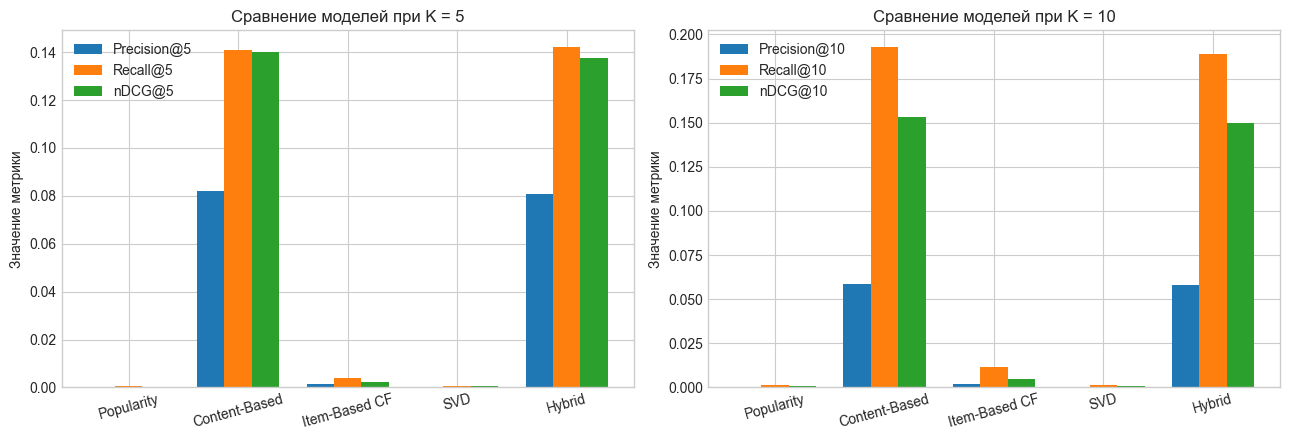

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

x = np.arange(len(results_df))
w = 0.25

axes[0].bar(x - w, results_df["Precision@5"], w, label="Precision@5")
axes[0].bar(x, results_df["Recall@5"], w, label="Recall@5")
axes[0].bar(x + w, results_df["nDCG@5"], w, label="nDCG@5")
axes[0].set_xticks(x)
axes[0].set_xticklabels(results_df.index, rotation=15)
axes[0].set_title("Сравнение моделей при K = 5")
axes[0].set_ylabel("Значение метрики")
axes[0].legend()

axes[1].bar(x - w, results_df["Precision@10"], w, label="Precision@10")
axes[1].bar(x, results_df["Recall@10"], w, label="Recall@10")
axes[1].bar(x + w, results_df["nDCG@10"], w, label="nDCG@10")
axes[1].set_xticks(x)
axes[1].set_xticklabels(results_df.index, rotation=15)
axes[1].set_title("Сравнение моделей при K = 10")
axes[1].set_ylabel("Значение метрики")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/07_models_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

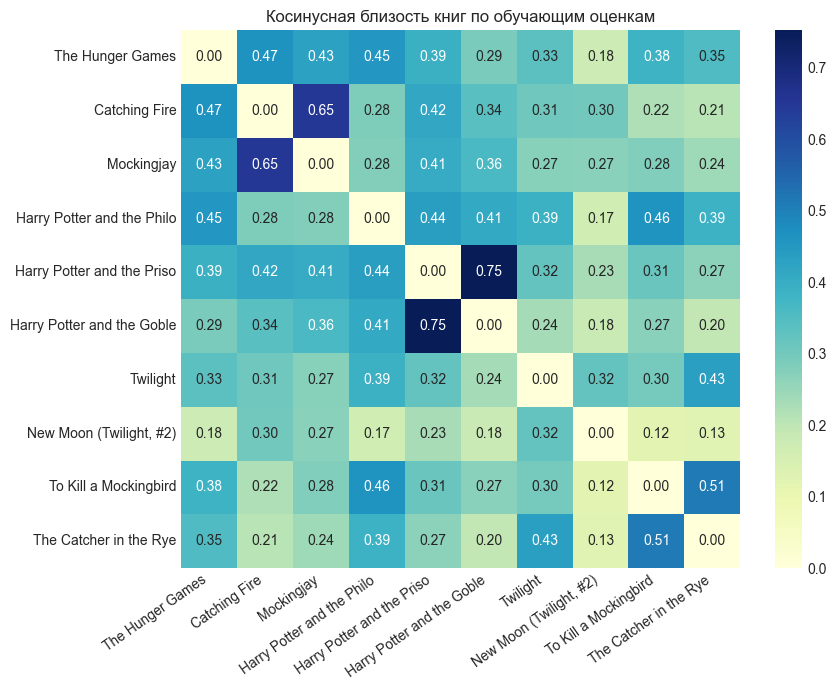

In [18]:
sample_ids = [1, 17, 20, 2, 18, 24, 3, 49, 4, 8]
sample_idx = np.array(sample_ids) - 1
item_vectors = normalize(final_state["R"].T.tocsr(), norm="l2", axis=1)
small_similarity = (item_vectors[sample_idx] @ item_vectors[sample_idx].T).toarray()
np.fill_diagonal(small_similarity, 0)
sample_names = books.iloc[sample_idx].clean_title.str.slice(0, 26)
plt.figure(figsize=(9, 7))
sns.heatmap(small_similarity, xticklabels=sample_names, yticklabels=sample_names,
            annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Косинусная близость книг по обучающим оценкам")
plt.xticks(rotation=35, ha="right"); plt.tight_layout()
plt.savefig(FIGURES / "05_item_cf_similarity_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## Этап 6. Холодный старт и выводы

### 6.1. Проверка холодного старта

Сначала посмотрю на результаты при разной длине истории: 1–4, 5–14 и 15+ обучающих оценок. Использую тех же пользователей из основного сравнения. Группы получатся разного размера, поэтому сравнивать их нужно осторожно.

Затем проверю **новых пользователей**, чьи оценки были целиком исключены из обучения. Возьму всех, у кого есть положительные отложенные оценки. Никаких личных сигналов у моделей для них нет, поэтому все будут возвращать Popularity.

Для **новых книг** возьму до 1000 пользователей с положительной оценкой одной из 100 отложенных книг и ненулевой обучающей историей. Буду искать рекомендации во всём каталоге, кроме уже оценённых в обучении книг. Попаданиями здесь считаю только новые отложенные книги. Поэтому эти метрики отвечают на другой вопрос и напрямую с основной таблицей не сравниваются.

users  Precision@5  Recall@5  nDCG@5
history_group model                                              
1–4           Content-Based    186       0.0398    0.1989  0.1290
              Hybrid           186       0.0398    0.1989  0.1390
              Item-Based CF    186       0.0022    0.0108  0.0048
              Popularity       186       0.0000    0.0000  0.0000
              SVD              186       0.0000    0.0000  0.0000
5–14          Content-Based   1031       0.0446    0.1623  0.1308
              Hybrid          1031       0.0458    0.1709  0.1323
              Item-Based CF   1031       0.0012    0.0047  0.0023
              Popularity      1031       0.0002    0.0005  0.0004
              SVD             1031       0.0002    0.0010  0.0010
15+           Content-Based   1283       0.1182    0.1156  0.1489
              Hybrid          1283       0.1150    0.1106  0.1419
              Item-Based CF   1283       0.0019    0.0021  0.0020
              Popularity      1283       0.0003    0.0004  0.0005
              SVD             1283       0.0002    0.0000  0.0001

Precision@5  Recall@5  nDCG@5  Precision@10  \
Сценарий           Модель                                                       
Новые пользователи Popularity          0.0020    0.0002  0.0023        0.0027   
                   Content-Based       0.0020    0.0002  0.0023        0.0027   
                   Item-Based CF       0.0020    0.0002  0.0023        0.0027   
                   SVD                 0.0020    0.0002  0.0023        0.0027   
                   Hybrid              0.0020    0.0002  0.0023        0.0027   
Новые книги        Popularity          0.0000    0.0000  0.0000        0.0000   
                   Content-Based       0.0372    0.1551  0.1080        0.0249   
                   Item-Based CF       0.0000    0.0000  0.0000        0.0000   
                   SVD                 0.0000    0.0000  0.0000        0.0000   
                   Hybrid              0.0542    0.2319  0.2047        0.0310   

                                  Recall@10  nDCG@10  
Сценарий           Модель                             
Новые пользователи Popularity        0.0009   0.0027  
                   Content-Based     0.0009   0.0027  
                   Item-Based CF     0.0009   0.0027  
                   SVD               0.0009   0.0027  
                   Hybrid            0.0009   0.0027  
Новые книги        Popularity        0.0000   0.0000  
                   Content-Based     0.2108   0.1266  
                   Item-Based CF     0.0000   0.0000  
                   SVD               0.0000   0.0000  
                   Hybrid            0.2618   0.2151

Новые пользователи: 299 ; новые книги: 1000 пользователей из 5488


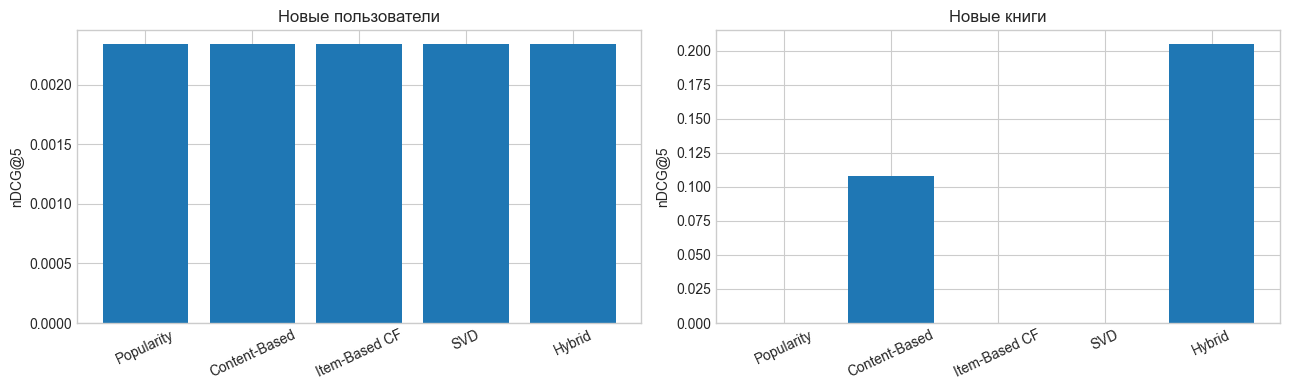

In [19]:
counts_for_eval = final_state["user_count"][per_user_metrics.user_id.to_numpy() - 1]
per_user_metrics["history_group"] = pd.cut(counts_for_eval, bins=[0, 4, 14, np.inf], labels=["1–4", "5–14", "15+"])
segment_results = (per_user_metrics.groupby(["history_group", "model"], observed=True)
                   .agg(users=("user_id", "size"), **{"Precision@5": ("Precision@5", "mean"),
                        "Recall@5": ("Recall@5", "mean"), "nDCG@5": ("nDCG@5", "mean")}))
display(segment_results.round(4))
segment_results.to_csv(RESULTS / "history_segments.csv")

new_users, _, n_new_users = evaluation_users(cold_user_test, final_state, len(cold_user_ids), SEED + 4, require_history=False)
new_book_users, _, n_new_book_users = evaluation_users(cold_book_test, final_state, 1000, SEED + 5)
assert (final_state["user_count"][cold_user_ids - 1] == 0).all()
assert (final_state["item_count"][cold_book_ids - 1] == 0).all()
new_user_results, _ = evaluate_ranking(final_state, cold_user_test, new_users, selected_weights)
new_book_results, _ = evaluate_ranking(final_state, cold_book_test, new_book_users, selected_weights)
cold_results = pd.concat({"Новые пользователи": new_user_results, "Новые книги": new_book_results}, names=["Сценарий", "Модель"])
display(cold_results.round(4))
print("Новые пользователи:", len(new_users), "; новые книги:", len(new_book_users), "пользователей из", n_new_book_users)
cold_results.to_csv(RESULTS / "cold_start_comparison.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, title, table in zip(axes, ["Новые пользователи", "Новые книги"], [new_user_results, new_book_results]):
    ax.bar(table.index, table["nDCG@5"])
    ax.set_title(title); ax.set_ylabel("nDCG@5"); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.savefig(FIGURES / "08_cold_start.png", dpi=150, bbox_inches="tight"); plt.show()

### 6.2. Насколько заметна разница между моделями?

Сравню гибрид с лучшей одиночной моделью по validation nDCG@5. Так соперник будет выбран без просмотра тестовых результатов.

Посчитаю разность тестового nDCG@5 для каждого пользователя и построю 95% bootstrap-интервал средней разности, 2000 раз выбирая пользователей с возвращением. Если в интервал попадёт ноль, оснований говорить об уверенном преимуществе не будет. Такой интервал показывает разброс по пользователям, но не учитывает другие разбиения данных и повторные обучения.

In [20]:
best_single = validation_baselines["nDCG@5"].idxmax()
paired = per_user_metrics.pivot(index="user_id", columns="model", values="nDCG@5")
difference = (paired["Hybrid"] - paired[best_single]).to_numpy()
bootstrap_rng = np.random.default_rng(SEED + 6)
bootstrap_means = np.array([bootstrap_rng.choice(difference, len(difference), replace=True).mean() for _ in range(2000)])
ci_low, ci_high = np.quantile(bootstrap_means, [0.025, 0.975])
print(f"Hybrid − {best_single}: средняя разность nDCG@5 = {difference.mean():.5f}; 95% CI [{ci_low:.5f}, {ci_high:.5f}]")

Hybrid − Content-Based: средняя разность nDCG@5 = -0.00224; 95% CI [-0.00610, 0.00160]


### 6.3. Проверки

В конце проверю, что рекомендации не содержат уже оценённых книг, функции возвращают ту же выдачу, что используется при оценке, а SVD сортирует книги по прогнозу рейтинга. Также проверю новые и некорректные ID. Разбиение данных и формулы метрик проверены выше.

In [21]:
check_users = eval_users[:5]
check_scores = all_model_scores(final_state, check_users, selected_weights)
for row, user in enumerate(check_users):
    seen = set(final_state["seen"][user - 1].indices + 1)
    for model in MODELS:
        recs = recommend(int(user), 10, model)
        expected = top_indices(check_scores[model][row], 10) + 1
        assert np.array_equal(recs.id.to_numpy(), expected)
        assert not set(recs.id) & seen
        assert recs.id.is_unique
    svd_recs = get_recommendations(int(user), 10)
    assert svd_recs.predicted_rating.is_monotonic_decreasing
    for model in ("Popularity", "Item-Based CF", "SVD"):
        ids = recommend(int(user), 10, model).id.to_numpy()
        pair_preds = predict_rating_pairs(final_state, np.full(len(ids), user), ids, model)
        assert np.allclose(pair_preds, check_scores[model][row, ids - 1], atol=2e-5)
for model in MODELS:
    assert np.array_equal(recommend(n_users + 1, 10, model).id, get_popular_books(10).id)
assert 1 not in set(get_similar_books(1).id)
for invalid in (0, -1, 1.5, True):
    try:
        get_recommendations(invalid)
        raise AssertionError("Невалидный ID был принят")
    except ValueError:
        pass
try:
    get_similar_books(n_books + 1)
    raise AssertionError("Невалидный ID книги был принят")
except ValueError:
    pass
assert np.allclose(new_user_results.to_numpy(), new_user_results.iloc[0].to_numpy()[None, :])
assert np.isfinite(results_df.drop(columns="RMSE").to_numpy()).all()
no_likes_users = np.flatnonzero((final_state["positive"].getnnz(axis=1) == 0) & (final_state["user_count"] > 0))
for u in no_likes_users[:3]:
    for model in ("Content-Based", "Hybrid"):
        assert np.array_equal(recommend(int(u + 1), 10, model).id, recommend(int(u + 1), 10, "Popularity").id)
for bad_n in (0, -1, 1.5, True):
    try:
        get_recommendations(example_user, bad_n)
        raise AssertionError("Невалидное N было принято")
    except ValueError:
        pass

print("Все проверки прошли.")

Все проверки прошли.


### 6.4. Выводы

Подставлю числа из итоговых таблиц, чтобы выводы оставались актуальными после повторного запуска.

In [22]:
best_rank = results_df["nDCG@5"].idxmax()
best_rmse = results_df["RMSE"].idxmin()
best_cold_book = new_book_results["nDCG@5"].idxmax()
uncertainty = ("интервал включает ноль, убедительного преимущества не видно" if ci_low <= 0 <= ci_high
               else "интервал целиком выше нуля" if ci_low > 0 else "интервал целиком ниже нуля")
summary_text = f"""
1. **Прогноз рейтинга.** Меньше всего ошибается **{best_rmse}**: RMSE = **{results_df.loc[best_rmse, 'RMSE']:.4f}**. SVD обучается именно на ошибке прогноза оценок. CF опирается на соседние книги, а Popularity не учитывает, кто выставляет оценку.
2. **Топ рекомендаций.** По nDCG@5 лучший результат у **{best_rank}**: **{results_df.loc[best_rank, 'nDCG@5']:.4f}**. Precision@5 этой модели — **{results_df.loc[best_rank, 'Precision@5']:.4f}**. Получается, точный прогноз рейтинга и хороший порядок рекомендаций — разные задачи.
3. **Гибрид.** Его nDCG@5 равен **{results_df.loc['Hybrid', 'nDCG@5']:.4f}**. Разность с {best_single} — **{difference.mean():.5f}**, 95% bootstrap-интервал — **[{ci_low:.5f}; {ci_high:.5f}]**: {uncertainty}. По одному факту смешивания моделей нельзя сделать вывод, что результат стал лучше.
4. **Новые пользователи.** Без истории все модели вернули Popularity. Чтобы рекомендации стали личными, нужно хотя бы несколько оценок или стартовый выбор интересов.
5. **Новые книги.** Здесь лучший nDCG@5 у **{best_cold_book}**: **{new_book_results.loc[best_cold_book, 'nDCG@5']:.4f}**. Название, автор и теги позволяют оценить сходство новой книги с интересами пользователя даже без оценок самой книги. Но попадание в топ всё равно зависит от остальных книг и качества тегов.
6. **Ограничения.** В нашем файле у книги не больше примерно 100 оценок. Если тестовой оценки нет, рекомендация не засчитывается как попадание, хотя книга могла бы понравиться. Поэтому top-N метрики могут быть низкими. Эти результаты относятся к выбранному случайному разбиению и не показывают напрямую, как система будет работать в сервисе.
"""
display(Markdown(summary_text))
(RESULTS / "conclusions.md").write_text(summary_text.strip() + "\n", encoding="utf-8")
run_summary = {
    "seed": SEED, "dataset_ratings": len(ratings), "users": n_users, "books": n_books,
    "splits": {name: len(frame) for name, frame in parts.items()},
    "svd_parameters": svd_parameters, "hybrid_weights_CF_SVD_Content": list(selected_weights),
    "ranking_users": len(eval_users), "ranking_eligible": n_eligible,
    "validation_ranking_users": len(valid_users), "cold_users_evaluated": len(new_users),
    "cold_book_users_evaluated": len(new_book_users), "cold_books": len(cold_book_ids),
    "best_ranking": best_rank, "best_RMSE": best_rmse, "best_cold_book": best_cold_book,
    "hybrid_difference_vs": best_single, "hybrid_ndcg5_difference": float(difference.mean()),
    "hybrid_difference_CI95": [float(ci_low), float(ci_high)],
    "versions": {name: importlib.metadata.version(name) for name in
                 ["numpy", "pandas", "scipy", "scikit-learn", "scikit-surprise", "matplotlib", "seaborn"]}
}
(RESULTS / "run_summary.json").write_text(json.dumps(run_summary, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
svd_search.to_csv(RESULTS / "svd_validation.csv", index=False)
weight_search.to_csv(RESULTS / "hybrid_validation.csv", index=False)


1. **Прогноз рейтинга.** Меньше всего ошибается **SVD**: RMSE = **0.8228**. SVD обучается именно на ошибке прогноза оценок. CF опирается на соседние книги, а Popularity не учитывает, кто выставляет оценку.
2. **Топ рекомендаций.** По nDCG@5 лучший результат у **Content-Based**: **0.1400**. Precision@5 этой модели — **0.0820**. Получается, точный прогноз рейтинга и хороший порядок рекомендаций — разные задачи.
3. **Гибрид.** Его nDCG@5 равен **0.1377**. Разность с Content-Based — **-0.00224**, 95% bootstrap-интервал — **[-0.00610; 0.00160]**: интервал включает ноль, убедительного преимущества не видно. По одному факту смешивания моделей нельзя сделать вывод, что результат стал лучше.
4. **Новые пользователи.** Без истории все модели вернули Popularity. Чтобы рекомендации стали личными, нужно хотя бы несколько оценок или стартовый выбор интересов.
5. **Новые книги.** Здесь лучший nDCG@5 у **Hybrid**: **0.2047**. Название, автор и теги позволяют оценить сходство новой книги с интересами пользователя даже без оценок самой книги. Но попадание в топ всё равно зависит от остальных книг и качества тегов.
6. **Ограничения.** В нашем файле у книги не больше примерно 100 оценок. Если тестовой оценки нет, рекомендация не засчитывается как попадание, хотя книга могла бы понравиться. Поэтому top-N метрики могут быть низкими. Эти результаты относятся к выбранному случайному разбиению и не показывают напрямую, как система будет работать в сервисе.


### Сильные и слабые стороны моделей

| Модель | Что удобно | Какие есть ограничения |
|---|---|---|
| Popularity | Простая и быстрая, работает без истории пользователя | Одинаковая выдача для всех, новые книги не проходят порог |
| Content-Based | Можно рекомендовать книгу без оценок и объяснить сходство тегами | Нужна история пользователя, результат зависит от качества тегов |
| Item-Based CF | Использует связи между оценками, прогноз можно объяснить соседями | Мало общих оценок — ненадёжные сходства; поиск соседей дорогой |
| SVD | Компактные факторы, хороший прогноз рейтинга | Низкий RMSE не гарантирует хороший top-N, для новых объектов нет обученных факторов |
| Hybrid | Позволяет менять подход в зависимости от доступных данных | Нужно подбирать веса и проверять, помогает ли смешивание |

Дальше я бы попробовал уменьшать сходства книг с малым числом общих оценок и подобрать K на validation. Для задачи ранжирования стоит проверить ALS, BPR или LightFM. Файл `to_read.csv` можно использовать как дополнительный неявный сигнал.

В контентную модель можно добавить аннотации и текстовые эмбеддинги, например Sentence-BERT. Новым пользователям помог бы короткий опрос об интересах. Если появятся даты взаимодействий, стоит повторить сравнение на временном разбиении. Также пока не проверялись разнообразие рекомендаций, покрытие каталога и время выдачи.

В итоге получился учебный прототип. Он позволяет сравнить подходы на одном датасете, но для настоящего сервиса ещё понадобятся проверки на реальных пользователях.

### Сохранение результатов

В последней ячейке сохраню таблицы и обновлю README по результатам этого запуска.

In [23]:
def markdown_table(table):
    headers = [table.index.name or "Модель", *map(str, table.columns)]
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    for name, row in table.iterrows():
        values = ["—" if pd.isna(x) else f"{x:.4f}" for x in row]
        lines.append("| " + " | ".join([str(name), *values]) + " |")
    return "\n".join(lines)


readme = f"""# Книжная рекомендательная система

Домашнее задание по модулю «Рекомендательные системы». На Goodbooks-10k я сравнил Popularity, контентную модель, Item-Based CF, SVD и гибрид.

Основное решение с кодом, графиками и пояснениями — в [ноутбуке](book_recommendation_system.ipynb).

## Как запустить

Я запускал работу на Python 3.13.7. Версии библиотек указаны в `requirements.txt`. Данные уже лежат в `data/`.
Команды нужно выполнять из папки проекта:

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
python -m ipykernel install --sys-prefix --name rec-system --display-name "Python (rec-system)"
python -m notebook book_recommendation_system.ipynb
```

В Jupyter нужно выбрать ядро **Python (rec-system)** и выполнить **Restart Kernel and Run All**.
Можно запустить весь ноутбук и без интерфейса:

```bash
python -m nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=rec-system --ExecutePreprocessor.timeout=600 book_recommendation_system.ipynb
```

После выполнения графики сохраняются в `figures/`, таблицы — в `results/`. Этот README тоже обновляется по итогам запуска.

## Что сделано

- Посмотрел на оценки, активность пользователей, популярность книг и частые теги.
- Разделил данные на train, validation и test. Параметры выбирал на validation.
- Обучил четыре модели из задания и добавил гибрид.
- Сравнил модели по Precision@K, Recall@K и nDCG@K при K=5 и K=10. Для моделей прогноза рейтинга также посчитал RMSE.
- Отдельно проверил пользователей с короткой историей, совсем новых пользователей и новые книги.

## Данные и разбиение

В локальной версии Goodbooks-10k после удаления повторяющихся пар осталось {len(ratings):,} оценок, {n_users:,} пользователей и {n_books:,} книг.
У книги здесь не больше примерно 100 оценок. Дат взаимодействий нет, поэтому разбиение случайное.

Для холодного старта сначала отложил 300 пользователей целиком и 100 книг со всеми оценками остальных пользователей.
Оставшиеся данные разделил внутри каждого пользователя:

- train — {len(train_df):,} оценок;
- validation — {len(valid_df):,};
- test — {len(test_df):,}.

После выбора параметров обучил модели на train + validation: {len(train_valid):,} оценках.

Для оценки топа случайно выбрал {len(eval_users):,} пользователей из {n_eligible:,}, у которых есть история в обучении и хотя бы одна тестовая оценка 4 или 5. Такие книги считаю релевантными.
В основном сравнении модели ранжируют все книги с обучающими оценками, исключая уже оценённые пользователем. RMSE считается по всем {len(test_df):,} оценкам основного test.

Средние и частоты для моделей посчитаны по обучению. Готовые счётчики Goodreads использовались только в EDA.
Название, автор и теги считаются доступными и для новых книг — проверить их состояние на прошлую дату по этим данным нельзя.

## Модели

- **Popularity:** средний рейтинг книги с порогом хотя бы {MIN_RATINGS} обучающих оценок.
- **Content-Based:** TF-IDF названия, автора и тегов; профиль пользователя по его оценкам 4 и 5.
- **Item-Based CF:** косинусная близость, {K_NEIGHBORS} соседей, прогноз с учётом среднего пользователя. Сходства считаются блоками.
- **SVD:** `surprise.SVD`, число факторов — {svd_parameters['n_factors']}, эпох — {svd_parameters['n_epochs']}, регуляризация — {svd_parameters['reg']}. Книги сортируются по предсказанному рейтингу.
- **Hybrid:** веса CF/SVD/Content для активных пользователей — {selected_weights}. При 1–4 оценках веса равны (0.2, 0.1, 0.7). Для новых книг используется контент, для новых пользователей — Popularity.

В функциях `book_id` означает внутренний ID из `ratings.csv`, то есть поле `id` в `books.csv`.
У Content-Based и Hybrid нет прогноза оценки от 1 до 5, поэтому RMSE для них не считаю.

## Результаты

{markdown_table(results_df)}

{summary_text.strip()}

## Холодный старт

Из 300 отложенных пользователей у {len(new_users)} есть релевантные оценки. Без истории все модели вернули им одинаковую выдачу Popularity.

Для 100 новых книг проверил {len(new_book_users):,} пользователей с обучающей историей. В этом эксперименте рекомендации ищутся во всём каталоге, а попаданиями считаются только новые отложенные книги.
Поэтому напрямую сравнивать эти числа с основной таблицей нельзя.

{markdown_table(new_book_results.rename_axis('Модель'))}

## Проверки и файлы с результатами

В ноутбуке проверяются разбиение без пересечений, формулы метрик на простом примере, исключение прочитанных книг,
совпадение прогнозов с `surprise.SVD.predict`, сортировка рекомендаций и обработка некорректных ID.
Также проверяется, что функции выдают тот же результат, который используется при сравнении моделей.

- `results/model_comparison.csv` — основная таблица.
- `results/cold_start_comparison.csv` — результаты холодного старта.
- `results/history_segments.csv` — группы по длине истории.
- `results/ranking_per_user.csv` — метрики отдельных пользователей.
- `results/svd_validation.csv`, `results/hybrid_validation.csv` — подбор параметров.
- `results/run_summary.json`, `results/conclusions.md` — настройки запуска и выводы.

## Что можно попробовать дальше

Я бы начал с подбора числа соседей CF и учёта того, сколько у двух книг общих оценок.
Для ранжирования можно попробовать ALS/BPR, а для контента — аннотации и текстовые эмбеддинги.
Новым пользователям помог бы небольшой опрос об интересах. Если появятся даты оценок, стоит повторить сравнение с разбиением по времени.
"""
# Убираем отступ шаблона, сохраняя Markdown-таблицы и блоки команд.
readme = "\n".join(line[4:] if line.startswith("    ") else line for line in readme.splitlines()).strip() + "\n"
Path("README.md").write_text(readme, encoding="utf-8")
print("Результаты и README сохранены.")

Результаты и README сохранены.
